TITANIC SURVIVAL PREDICTION PROJECT

Dataset loaded successfully!

First five records:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            1

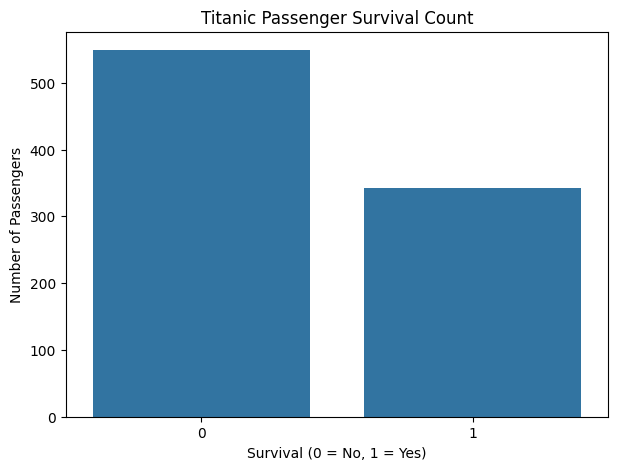

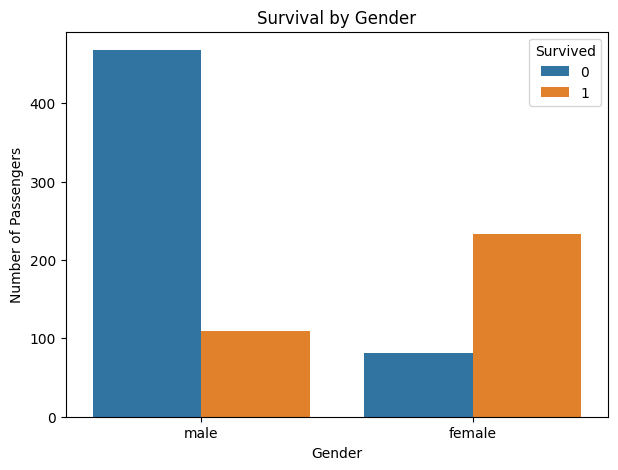

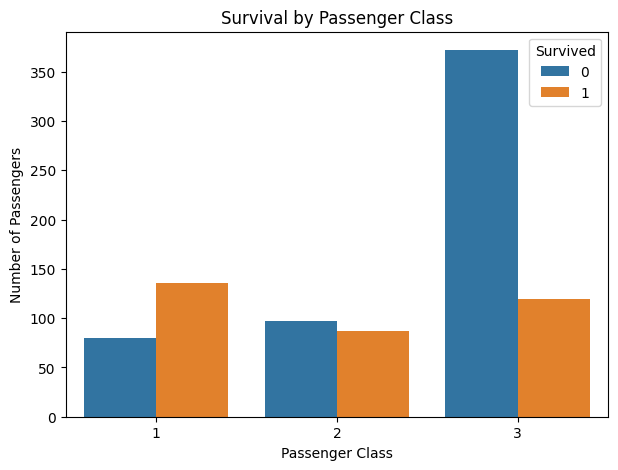


Training records: 712
Testing records: 179

Machine Learning model trained successfully!

Actual survival values:
[0 0 1 0 1 1 1 0 0 0]

Predicted survival values:
[0 0 0 0 1 0 1 0 0 0]

MODEL PERFORMANCE
----------------------------------------
Accuracy: 80.45 %

Classification Report:
              precision    recall  f1-score   support

Not Survived       0.81      0.89      0.85       110
    Survived       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



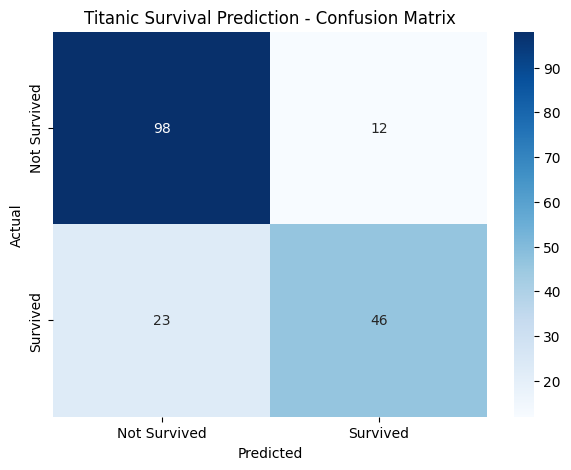


NEW PASSENGER PREDICTION:
Prediction: Survived

FINAL PROJECT SUMMARY
Project: Titanic Survival Prediction
Dataset records: 891
Features used: 7
Machine Learning Algorithm: Logistic Regression
Model Accuracy: 80.45 %

PROJECT COMPLETED SUCCESSFULLY!


In [2]:

# ======================================================
# MODULE 06 - FINAL DATA SCIENCE PROJECT
# TITANIC SURVIVAL PREDICTION
# ======================================================

# 1. Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TITANIC SURVIVAL PREDICTION PROJECT")
print("=" * 50)


# 2. Load dataset directly from GitHub

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("\nDataset loaded successfully!")
print("\nFirst five records:")
print(df.head())

print("\nDataset shape:")
print(df.shape)


# 3. Explore the dataset

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())


# 4. Data cleaning

df = df.drop_duplicates()

print("\nDuplicate records removed.")
print("Current dataset size:", df.shape)


# 5. Data analysis

print("\nSurvival counts:")
print(df["Survived"].value_counts())

print("\nSurvival percentage:")
print((df["Survived"].value_counts(normalize=True) * 100).round(2))


# 6. Visualisation - Survival count

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Survived")

plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()


# 7. Visualisation - Survival by gender

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()


# 8. Visualisation - Survival by passenger class

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Pclass", hue="Survived")

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()


# 9. Prepare features and target

# We exclude passenger names, ticket numbers and cabin details.
# Survived is the value we want to predict.

features = [
    "Pclass", "Sex", "Age",
    "SibSp", "Parch", "Fare", "Embarked"
]

X = df[features]
y = df["Survived"]

numeric_features = [
    "Pclass", "Age", "SibSp", "Parch", "Fare"
]

categorical_features = ["Sex", "Embarked"]


# 10. Handle missing values and convert categories

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


# 11. Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


# 12. Build and train Machine Learning model

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("\nMachine Learning model trained successfully!")


# 13. Make predictions

predictions = model.predict(X_test)

print("\nActual survival values:")
print(y_test.head(10).values)

print("\nPredicted survival values:")
print(predictions[:10])


# 14. Evaluate model performance

accuracy = accuracy_score(y_test, predictions)

print("\nMODEL PERFORMANCE")
print("-" * 40)

print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(
    y_test,
    predictions,
    target_names=["Not Survived", "Survived"],
    zero_division=0
))


# 15. Confusion matrix

cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.title("Titanic Survival Prediction - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


# 16. Predict survival for a new passenger

new_passenger = pd.DataFrame([{
    "Pclass": 3,
    "Sex": "female",
    "Age": 25,
    "SibSp": 0,
    "Parch": 0,
    "Fare": 10,
    "Embarked": "S"
}])

new_prediction = model.predict(new_passenger)

print("\nNEW PASSENGER PREDICTION:")

if new_prediction[0] == 1:
    print("Prediction: Survived")
else:
    print("Prediction: Did not survive")


# 17. Final project summary

print("\n" + "=" * 50)
print("FINAL PROJECT SUMMARY")
print("=" * 50)

print("Project: Titanic Survival Prediction")
print("Dataset records:", len(df))
print("Features used:", len(features))
print("Machine Learning Algorithm: Logistic Regression")
print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nPROJECT COMPLETED SUCCESSFULLY!")
